# Custo de equilíbrio

Combina os três experimentos no modelo da seção 4 de `../artigo.md`:

- tau_c(N): `../dados/tau_c.csv`, de `1_var_classico.ipynb` (já escalado para cada erro-alvo em `../dados/tau_q.csv`);
- c e beta: `../dados/backtest_c_beta.csv`, de `2_backtest.ipynb` (mediana por N da lei da perda média; acima de N = 64 usa N = 64; a lei do ES entra na sensibilidade);
- T_q(N): `../dados/tau_q.csv`, de `3_var_quantico.ipynb`.

Tudo em dólares, para uma mesa com limite de VaR de `LIMITE_MESA` milhões, com recálculo a cada minuto do pregão. A carga genérica fica de fora: o custo dela já é inviável em N = 8.

```
L(tau)    = c * tau^beta / 390 * LIMITE_MESA        custo do atraso por recálculo
dR        = L(tau_c) - L(tau_q),   tau_q = T_q / r   ganho por recálculo com taxa r de portas T
X         = C_c + dR                                custo de equilíbrio por execução
p*        = X / tau_q                               preço por segundo de equilíbrio
p_T,max   = (C_c + L(tau_c)) / T_q                  preço por porta T com quântico instantâneo
r*        = T_q / tau_c                             taxa de empate em tempo
r_IBM     = menor r com p*(r) >= preço da IBM       taxa em que o preço atual por segundo fecha a conta
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MINUTOS = 390                      # recálculos por dia
LIMITE_MESA = 100.0                # limite de VaR da mesa, em US$ milhões; o ganho escala linearmente com ele
PRECO_IBM_S = 1.60                 # US$ por segundo, IBM pay-as-you-go
PRECO_CLASSICO_S = 0.10 / 3600     # US$ por segundo de uma vCPU; premissa de ordem de grandeza
TAXAS_T = [1e4, 1e6, 1e8]          # cenários de portas T por segundo

tq = pd.read_csv("../dados/tau_q.csv")
tq = tq[tq["carga"] != "generica"]
cb = pd.read_csv("../dados/backtest_c_beta.csv")
lei = cb.groupby("N")[["c", "beta", "c_es", "beta_es"]].median()


def custo_atraso(tau, c, beta, limite=LIMITE_MESA):
    """L(tau) por recálculo, em US$, para uma mesa com limite de VaR de `limite` milhões."""
    return c * np.asarray(tau) ** beta / MINUTOS * limite


def equilibrio(tc, T, c, beta, limite=LIMITE_MESA):
    """Teto do ganho, p_T,max, r* e r_IBM para uma lei de atraso (c, beta) e um limite de mesa."""
    Cc = tc * PRECO_CLASSICO_S
    teto = custo_atraso(tc, c, beta, limite)
    r_star = T / tc
    taxas = r_star * np.logspace(0, 6, 3001)[1:]       # de r* a 10^6 r*
    p = (Cc + teto - custo_atraso(T / taxas, c, beta, limite)) * taxas / T
    ok = p >= PRECO_IBM_S
    return {"C_c": Cc, "teto_dR": teto, "p_T_max": (Cc + teto) / T, "r_estrela": r_star,
            "r_IBM": taxas[ok.argmax()] if ok.any() else np.nan}, (taxas, p)

In [2]:
linhas = []
curvas = {}
for _, r in tq.iterrows():
    N, tc, T = int(r["N"]), r["tau_c_s"], r["T_total"]
    c, beta = lei.loc[min(N, 64), ["c", "beta"]]
    e, curvas[N, r["eps"], r["carga"]] = equilibrio(tc, T, c, beta)
    linha = {"N": N, "eps": r["eps"], "carga": r["carga"], "tau_c_s": tc, "T_q": T, **e,
             "X_max": e["C_c"] + e["teto_dR"]}
    for t in TAXAS_T:
        linha[f"X_{t:.0e}"] = e["C_c"] + e["teto_dR"] - custo_atraso(T / t, c, beta)
    linhas.append(linha)

eq = pd.DataFrame(linhas)
eq["r_IBM_sobre_r_estrela"] = eq["r_IBM"] / eq["r_estrela"]
eq["ganho_anual_max"] = eq["teto_dR"] * MINUTOS * 252
eq.to_csv("../dados/equilibrio.csv", index=False)
cols = ["N", "eps", "carga", "tau_c_s", "C_c", "teto_dR", "ganho_anual_max", "p_T_max", "r_estrela", "r_IBM", "r_IBM_sobre_r_estrela"]
print(eq[cols].to_string(index=False, float_format=lambda x: f"{x:.3g}"))
print("\nmaior X nos cenários de hardware:", eq[[f"X_{t:.0e}" for t in TAXAS_T]].max().round(2).to_dict())

  N   eps       carga  tau_c_s      C_c  teto_dR  ganho_anual_max  p_T_max  r_estrela    r_IBM  r_IBM_sobre_r_estrela
  1  0.01    cholesky  0.00047 1.31e-08   0.0273         2.68e+03 3.98e-12   1.46e+13 1.52e+13                   1.04
  1  0.01 fator unico  0.00047 1.31e-08   0.0273         2.68e+03  2.1e-12   2.76e+13 2.88e+13                   1.04
  1 0.001    cholesky  0.00493 1.37e-07    0.137         1.35e+04 1.94e-13   1.43e+14 1.55e+14                   1.09
  1 0.001 fator unico  0.00493 1.37e-07    0.137         1.35e+04 1.02e-13   2.72e+14 2.95e+14                   1.09
  2  0.01    cholesky  0.00261 7.26e-08    0.101         9.92e+03 7.09e-12   5.45e+12 5.79e+12                   1.06
  2  0.01 fator unico  0.00261 7.26e-08    0.101         9.92e+03 4.92e-12   7.85e+12 8.34e+12                   1.06
  2 0.001    cholesky   0.0436 1.21e-06    0.665         6.53e+04 4.23e-13    3.6e+13 4.15e+13                   1.15
  2 0.001 fator unico   0.0436 1.21e-06    0.665        

## Sensibilidade

Erro de 1%, carga com fator único. Varia a medida do custo do atraso (perda média ou ES de 97,5%), a carteira (as que ficam nos quartis de 25% e 75% do teto do ganho, entre os 20 sorteios) e o limite de VaR da mesa.

In [3]:
sel = tq[(tq["eps"] == 0.01) & (tq["carga"] == "fator unico")].set_index("N")
linhas_s = []
for N in (8, 32, 64):
    tc, T = sel.loc[N, "tau_c_s"], sel.loc[N, "T_total"]
    casos = {"base: perda média, mediana": (lei.loc[N, "c"], lei.loc[N, "beta"], LIMITE_MESA),
             "ES 97,5%, mediana": (lei.loc[N, "c_es"], lei.loc[N, "beta_es"], LIMITE_MESA)}
    g = cb[cb["N"] == N].dropna(subset=["c", "beta"])
    if len(g) > 1:
        tetos = g["c"] * tc ** g["beta"]
        for q in (0.25, 0.75):
            i = (tetos - tetos.quantile(q)).abs().idxmin()
            casos[f"perda média, carteira no quartil de {q:.0%}"] = (g.loc[i, "c"], g.loc[i, "beta"], LIMITE_MESA)
    for lim in (1, 10, 1000):
        casos[f"limite de US$ {lim:g} milhões"] = (lei.loc[N, "c"], lei.loc[N, "beta"], lim)
    for nome, (c, b, lim) in casos.items():
        e, _ = equilibrio(tc, T, c, b, lim)
        linhas_s.append({"N": N, "caso": nome, "teto_dR": e["teto_dR"], "p_T_max": e["p_T_max"],
                         "r_IBM_sobre_r_estrela": e["r_IBM"] / e["r_estrela"]})
sens = pd.DataFrame(linhas_s)
sens.to_csv("../dados/sensibilidade.csv", index=False)
print(sens.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

 N                                    caso  teto_dR  p_T_max  r_IBM_sobre_r_estrela
 8              base: perda média, mediana    0.683 9.67e-12                   1.25
 8                       ES 97,5%, mediana     4.54 6.43e-11                   1.04
 8 perda média, carteira no quartil de 25%    0.483 6.85e-12                   1.34
 8 perda média, carteira no quartil de 75%     1.02 1.45e-11                   1.18
 8                 limite de US$ 1 milhões  0.00683 9.67e-14                   21.1
 8                limite de US$ 10 milhões   0.0683 9.67e-13                   3.27
 8              limite de US$ 1000 milhões     6.83 9.67e-11                   1.03
32              base: perda média, mediana     1.45 5.92e-12                   1.46
32                       ES 97,5%, mediana     7.85 3.21e-11                   1.08
32 perda média, carteira no quartil de 25%     1.31 5.36e-12                    1.5
32 perda média, carteira no quartil de 75%     1.64 6.71e-12                

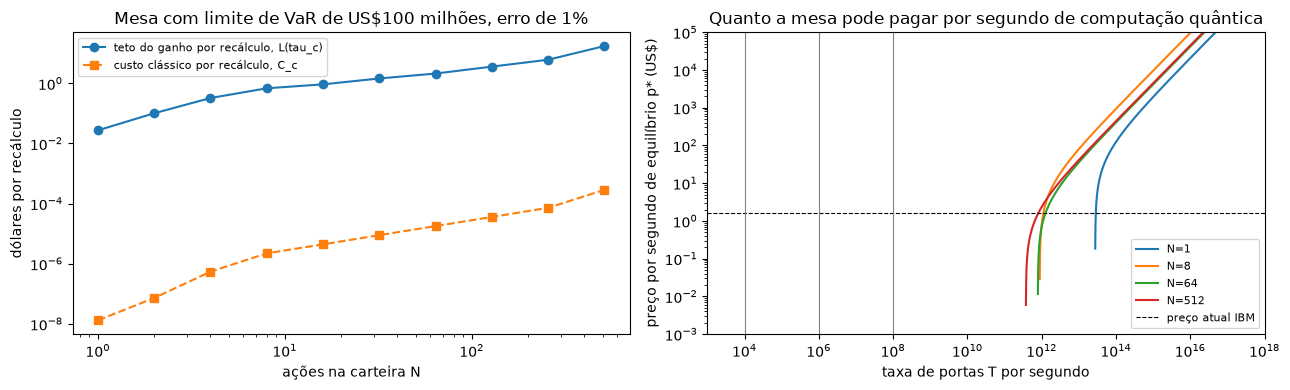

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

base = eq[(eq["eps"] == 0.01) & (eq["carga"] == "fator unico")]
ax[0].loglog(base["N"], base["teto_dR"], "o-", label="teto do ganho por recálculo, L(tau_c)")
ax[0].loglog(base["N"], base["C_c"], "s--", label="custo clássico por recálculo, C_c")
ax[0].set(xlabel="ações na carteira N", ylabel="dólares por recálculo",
          title=f"Mesa com limite de VaR de US${LIMITE_MESA:.0f} milhões, erro de 1%")
ax[0].legend(fontsize=8)

for N, cor in ((1, "C0"), (8, "C1"), (64, "C2"), (512, "C3")):
    taxas, p = curvas[N, 0.01, "fator unico"]
    ax[1].loglog(taxas, p, color=cor, label=f"N={N}")
ax[1].axhline(PRECO_IBM_S, color="k", lw=0.8, ls="--", label="preço atual IBM")
for t in TAXAS_T:
    ax[1].axvline(t, color="gray", lw=0.8)
ax[1].set(xlabel="taxa de portas T por segundo", ylabel="preço por segundo de equilíbrio p* (US$)",
          title="Quanto a mesa pode pagar por segundo de computação quântica", xlim=(1e3, 1e18), ylim=(1e-3, 1e5))
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../figuras/equilibrio.png", dpi=150)
plt.show()

## O que observar

- Nos cenários de 10^4 a 10^8 portas T por segundo, X é negativo para todo N: o quântico chega depois do clássico, e nenhum preço torna a adoção vantajosa.
- p_T,max é o teto do preço por porta T com hardware instantâneo.
- r_IBM / r* perto de 1 indica que, assim que o hardware fica mais rápido que o clássico, o preço atual por segundo já fecharia a conta. A sensibilidade mostra quanto isso depende da medida do custo do atraso, da carteira e do tamanho da mesa.